# 03: Evaluation, statistics and thesis figures

Reads the saved predictions in `outputs/runs/` and produces every Chapter 4 artifact.
Everything written to `outputs/tables/*.csv` and `outputs/figures/*.png` 

| Output | Thesis home |
|---|---|
| `table_4_1_plane_auc.csv` | Table 4.1: plane-level performance |
| `table_4_2_exam_level.csv` | Table 4.2: examination-level performance |
| `table_4_3_pairwise.csv` | Table 4.3: paired DeLong tests, BH-corrected |
| `calibration_<task>.png` | section 4.4: reliability diagrams |
| `table_4_5_efficiency.csv` | Table 4.5: computational efficiency |
| `table_4_7_external.csv`, `roc_external.png` | section 4.7: external validation (only if KneeMRI prepared) |
| `figures/gradcam/*.png` | section 4.8: qualitative saliency analysis |
| `roc_fused.png`, `training_curves.png`, `confusion_*.png` | Chapter 4 figures |

In [ ]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import Config, get_device
from src import evaluate as E
from src import plots as P
from src import gradcam as G
from src.data import make_transform
from src.metrics import full_metrics, report_at_threshold, youden_threshold

P.setup_style()
cfg = Config(smoke_test=False).make_dirs() 

runs = E.collect_runs(cfg)
print(f"{len(runs)} completed runs found")

13 completed runs found


## 3.1 Plane-level performance

In [2]:
table_4_1 = E.plane_level_table(cfg, runs)
E.save_table(cfg, table_4_1, "table_4_1_plane_auc")
display(table_4_1)

saved -> /Users/john/programming/thesis-cnn/outputs/tables/table_4_1_plane_auc.csv


,Model,Plane,Seeds,AUC abnormal,AUC acl,AUC meniscus
0,A,axial,1,0.727 ± 0.000,0.711 ± 0.000,0.683 ± 0.000
1,A,coronal,1,0.592 ± 0.000,0.528 ± 0.000,0.583 ± 0.000
2,A,sagittal,1,0.705 ± 0.000,0.689 ± 0.000,0.647 ± 0.000
3,B,axial,1,0.926 ± 0.000,0.882 ± 0.000,0.772 ± 0.000
4,B,coronal,1,0.856 ± 0.000,0.912 ± 0.000,0.825 ± 0.000
5,B,sagittal,1,0.933 ± 0.000,0.880 ± 0.000,0.731 ± 0.000
6,C,axial,1,0.853 ± 0.000,0.922 ± 0.000,0.761 ± 0.000
7,C,coronal,1,0.897 ± 0.000,0.924 ± 0.000,0.789 ± 0.000
8,C,sagittal,1,0.789 ± 0.000,0.890 ± 0.000,0.720 ± 0.000
9,D,sagittal,1,0.877 ± 0.000,0.823 ± 0.000,0.698 ± 0.000


## 3.2 Multi-plane fusion and examination-level performance (Table 4.2)

Plane probabilities are fused per model, seed and task with L2-regularised logistic regression
fitted on tuning predictions only (section 3.7), then averaged across seeds. Operating
thresholds come from the tuning set via Youden's J (section 3.8) and are applied unchanged to
the test set. Model D trained on the sagittal plane only under budget, so no "fused" row (really is just a single plane). See Section 4

In [3]:
fused = E.fused_predictions(cfg, runs)

table_4_2 = E.exam_level_table(cfg, fused)
E.save_table(cfg, table_4_2, "table_4_2_exam_level")
display(table_4_2)

saved -> /Users/john/programming/thesis-cnn/outputs/tables/table_4_2_exam_level.csv


,Model,Task,AUC (95% CI),Sensitivity,Specificity,F1,Brier,ECE,Threshold
0,A,abnormal,0.744 (0.622–0.866),0.958 (0.897–0.984),0.400 (0.234–0.593),0.905,0.152,0.094,0.765
1,A,acl,0.736 (0.643–0.829),0.630 (0.496–0.746),0.712 (0.594–0.807),0.636,0.313,0.264,0.188
2,A,meniscus,0.701 (0.607–0.794),0.846 (0.725–0.920),0.382 (0.276–0.501),0.638,0.236,0.123,0.341
3,B,abnormal,0.937 (0.896–0.978),0.895 (0.817–0.942),0.720 (0.524–0.857),0.909,0.109,0.122,0.840
4,B,acl,0.928 (0.882–0.974),0.926 (0.824–0.971),0.712 (0.594–0.807),0.813,0.154,0.171,0.151
5,B,meniscus,0.807 (0.729–0.884),0.846 (0.725–0.920),0.603 (0.484–0.711),0.715,0.180,0.065,0.376
6,C,abnormal,0.906 (0.851–0.961),0.937 (0.869–0.971),0.640 (0.445–0.798),0.922,0.127,0.106,0.798
7,C,acl,0.932 (0.888–0.975),0.870 (0.756–0.936),0.848 (0.743–0.916),0.847,0.168,0.214,0.324
8,C,meniscus,0.809 (0.731–0.887),0.846 (0.725–0.920),0.603 (0.484–0.711),0.715,0.178,0.031,0.376
9,D,abnormal,0.877 (0.811–0.944),0.737 (0.640–0.815),0.840 (0.653–0.936),0.828,0.146,0.153,0.574


### Classification reports and confusion matrices

Per model and task, at the tuning-set Youden threshold

In [4]:
for m in sorted(fused):
    for t in cfg.tasks:
        tune, test = fused[m][t]["tune"], fused[m][t]["test"]
        thr = youden_threshold(tune["y"], tune["p"])
        print(f"\n=== Model {m} — {t} (threshold {thr:.3f}) ===")
        print(report_at_threshold(test["y"], test["p"], thr))
        met = full_metrics(test["y"], test["p"], thr)
        fig = P.confusion_figure(met["tp"], met["fp"], met["tn"], met["fn"], m, t,
                                 save=cfg.figures_dir / f"confusion_{m}_{t}.png")
        plt.close(fig)
print("Confusion matrices saved to outputs/figures/")


=== Model A — abnormal (threshold 0.765) ===
              precision    recall  f1-score   support

    negative       0.71      0.40      0.51        25
    positive       0.86      0.96      0.91        95

    accuracy                           0.84       120
   macro avg       0.79      0.68      0.71       120
weighted avg       0.83      0.84      0.82       120

saved -> /Users/john/programming/thesis-cnn/outputs/figures/confusion_A_abnormal.png

=== Model A — acl (threshold 0.188) ===
              precision    recall  f1-score   support

    negative       0.70      0.71      0.71        66
    positive       0.64      0.63      0.64        54

    accuracy                           0.68       120
   macro avg       0.67      0.67      0.67       120
weighted avg       0.67      0.68      0.67       120

saved -> /Users/john/programming/thesis-cnn/outputs/figures/confusion_A_acl.png

=== Model A — meniscus (threshold 0.341) ===
              precision    recall  f1-score   su

## 3.3 Pairwise comparisons (Table 4.3)

The six planned contrasts per task (section 3.8): paired DeLong tests on the same test
examinations, Benjamini-Hochberg corrected at FDR 0.05.

In [5]:
table_4_3 = E.pairwise_table(cfg, fused)
E.save_table(cfg, table_4_3, "table_4_3_pairwise")
display(table_4_3)

saved -> /Users/john/programming/thesis-cnn/outputs/tables/table_4_3_pairwise.csv


,Task,Contrast,dAUC,p,p (BH-adjusted),Significant (FDR 0.05)
0,abnormal,B vs A,+0.193,0.0003,0.0019,True
1,abnormal,C vs A,+0.162,0.0093,0.0278,True
2,abnormal,C vs B,-0.031,0.1780,0.2670,False
3,abnormal,E vs C,+0.015,0.3701,0.4898,False
4,abnormal,D vs E,-0.044,0.1216,0.1990,False
5,abnormal,D vs C,-0.029,0.3810,0.4898,False
6,acl,B vs A,+0.192,0.0000,0.0001,True
7,acl,C vs A,+0.196,0.0000,0.0002,True
8,acl,C vs B,+0.004,0.8629,0.9137,False
9,acl,E vs C,+0.003,0.8410,0.9137,False


## 3.4 Calibration (section 4.4)

Reliability diagrams per task. (Note that Brier score and ECE are already in Table 4.2)

saved -> /Users/john/programming/thesis-cnn/outputs/figures/calibration_abnormal.png
saved -> /Users/john/programming/thesis-cnn/outputs/figures/calibration_acl.png
saved -> /Users/john/programming/thesis-cnn/outputs/figures/calibration_meniscus.png


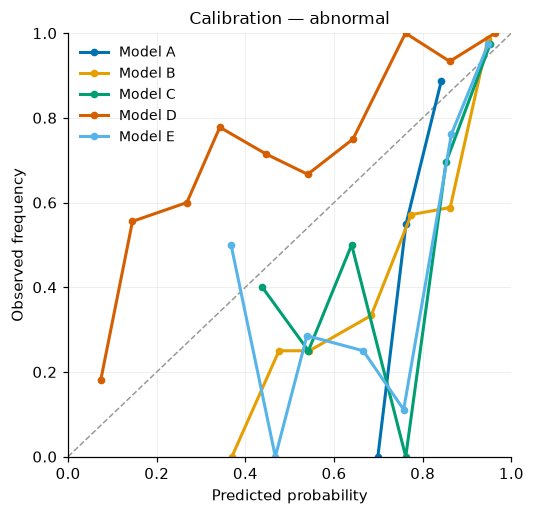

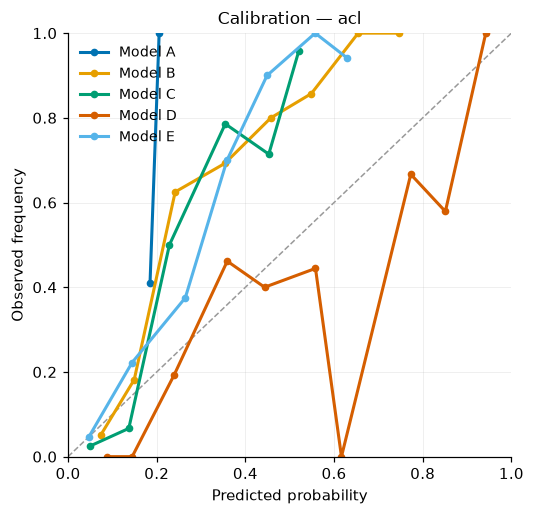

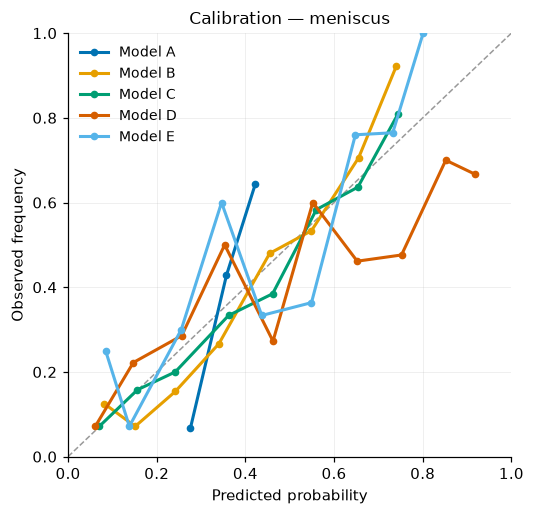

In [6]:
for t in cfg.tasks:
    P.reliability_figure(fused, t, save=cfg.figures_dir / f"calibration_{t}.png")

## 3.5 Computational efficiency (Table 4.5)

Parameters, mean epoch time, inference time per examination and peak accelerator memory 

In [7]:
table_4_5 = E.efficiency_table(cfg, runs)
E.save_table(cfg, table_4_5, "table_4_5_efficiency")
display(table_4_5)

saved -> /Users/john/programming/thesis-cnn/outputs/tables/table_4_5_efficiency.csv


,Model,Name,Parameters (M),Epoch time (min),Inference (s/exam),Peak memory (GB),Runs
0,A,Fully connected baseline,1.08,0.3,0.10,0.0,3
1,B,AlexNet slice CNN (pretrained),2.47,1.1,0.12,0.0,3
2,C,ResNet-18 slice CNN (pretrained),11.18,3.2,0.16,0.1,3
3,D,MONAI 3D DenseNet-121,11.25,3.2,0.05,0.1,1
4,E,ResNet-18 + MONAI pipeline,11.18,3.5,0.10,0.1,3


## 3.6 ROC curves and training curves (Chapter 4 figures)

saved -> /Users/john/programming/thesis-cnn/outputs/figures/roc_fused.png
saved -> /Users/john/programming/thesis-cnn/outputs/figures/training_curves.png


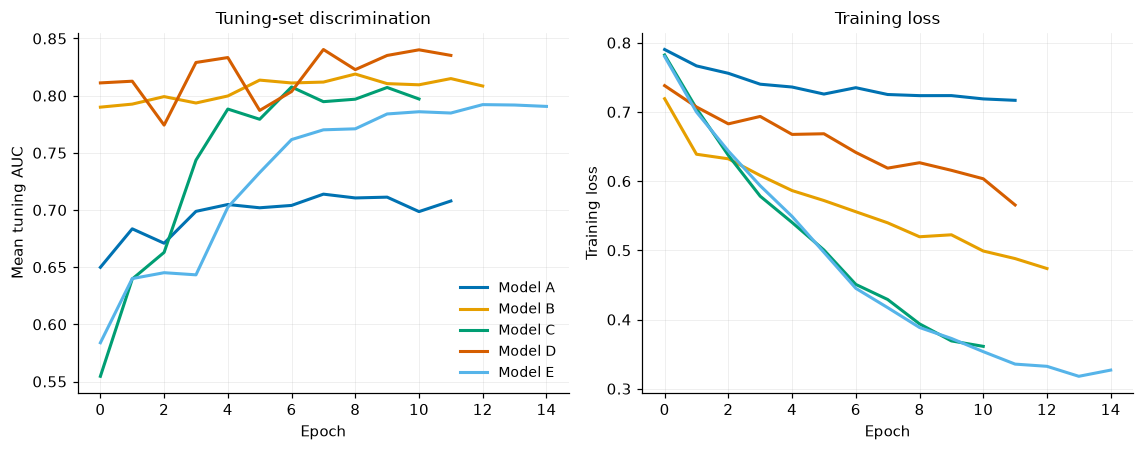

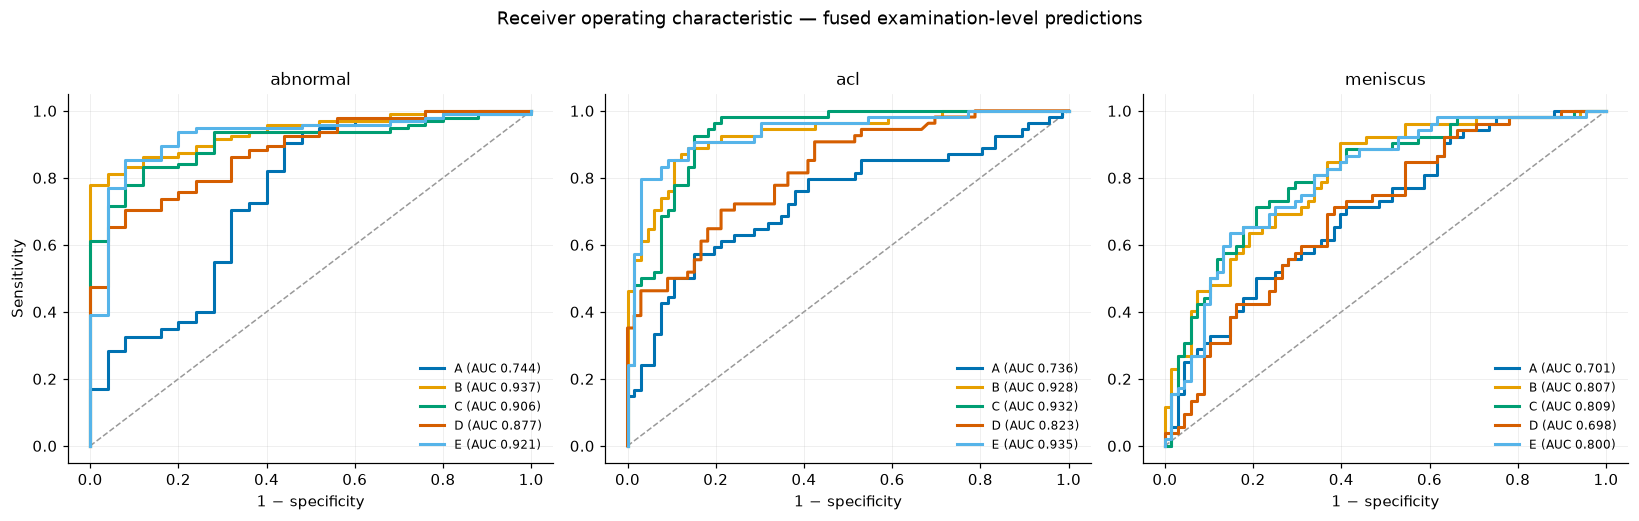

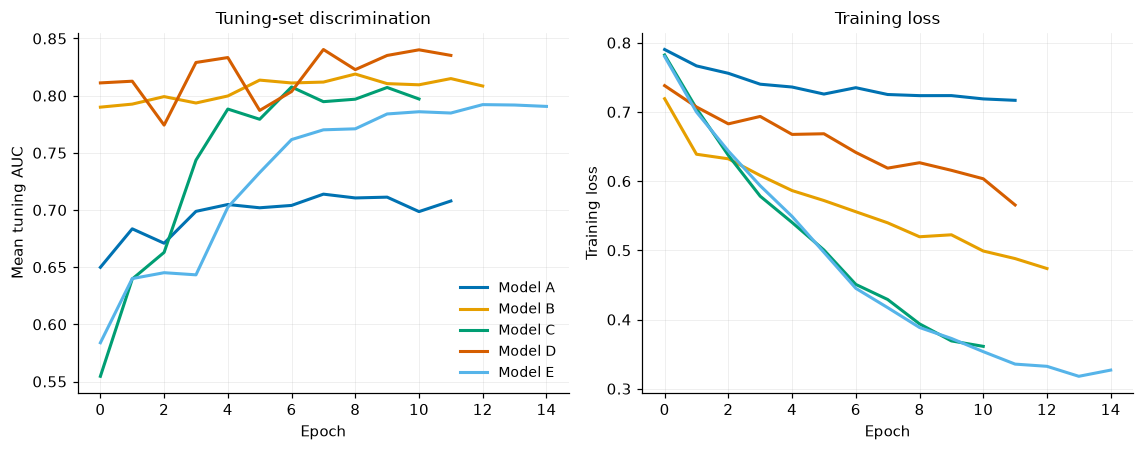

In [8]:
P.roc_grid(fused, cfg.tasks, save=cfg.figures_dir / "roc_fused.png")

sel = runs[runs.plane == "sagittal"]
hist = {m: E.load_history(cfg, g.iloc[0]["run_id"]) for m, g in sel.groupby("model_id")}
P.training_curves_figure(hist, save=cfg.figures_dir / "training_curves.png")

## 3.7 External validation (section 4.7, only if KneeMRI was prepared)

Zero-shot ACL transfer: the sagittal MRNet models applied unchanged to every KneeMRI
examination

In [9]:
try:
    table_4_7, ext_preds = E.external_validation(cfg, runs)
    E.save_table(cfg, table_4_7, "table_4_7_external")
    display(table_4_7)
    P.roc_figure(ext_preds, "External validation — ACL (zero-shot)",
                 save=cfg.figures_dir / "roc_external.png")
except FileNotFoundError as err:
    print("KneeMRI not prepared — skipping external validation:", err)

KneeMRI not prepared — skipping external validation: [Errno 2] No such file or directory: '/Users/john/programming/thesis-cnn/splits/kneemri_labels.csv'


## 3.8 Grad-CAM saliency (section 4.8)

For models C (2D) and D (3D): class-activation maps from the final convolutional stage for
true positives (highest-probability positive exams) and false negatives (lowest-probability
positives) (see section 3.10). Each figure has three panels: the raw slice, the Grad-CAM heat
map, and a derived detection box around the most activated region.

In [10]:
import torch

GRADCAM_MODELS = [m for m in ("C", "D") if m in runs.model_id.values]
N_EACH = 2
device = get_device()

for m in GRADCAM_MODELS:
    sel = runs[(runs.model_id == m) & (runs.plane == "sagittal")]
    model, log = E.load_trained(cfg, sel.iloc[0]["run_id"])
    engine = G.GradCAM(model, m)
    folder = cfg.data_root / "valid" / "sagittal"
    tf = make_transform(m, train=False)
    for t in cfg.tasks:
        picks = fused[m][t]["test"]
        tps, fns = G.pick_saliency_exams(picks, n_each=N_EACH)
        lookup = picks.set_index("id")
        for eid in dict.fromkeys(tps + fns):          # unique, order-preserving
            vol = np.load(folder / f"{eid}.npy")
            x = tf(vol)
            if m == "D":
                x = x.unsqueeze(0)
            cam = engine.compute(x.to(device), cfg.tasks.index(t))
            fig = G.gradcam_figure(vol, cam, m, t, eid, int(lookup.loc[eid, "y"]),
                                   float(lookup.loc[eid, "p"]),
                                   save=cfg.figures_dir / "gradcam" / f"gradcam_{m}_{t}_{eid}.png")
            plt.close(fig)
    del model, engine

print("Grad-CAM figures ->", cfg.figures_dir / "gradcam")

Grad-CAM figures -> /Users/john/programming/thesis-cnn/outputs/figures/gradcam


### Multi-plane visual comparison

The same examination seen from all three planes with model C's attention overlaid.
<br>
Useful for asking whether the model attends to the same region in every view (see section 4.8)

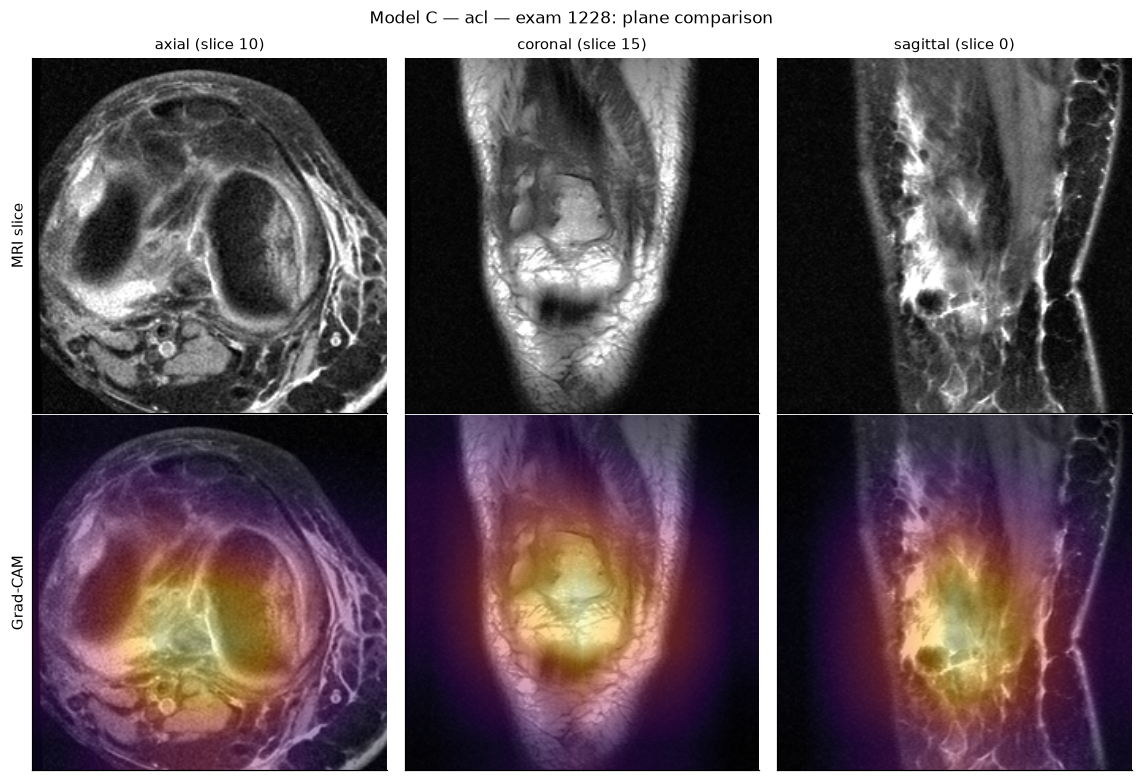

In [11]:
if "C" in runs.model_id.values:
    planes_avail = runs[runs.model_id == "C"].plane.unique().tolist()
    if len(planes_avail) >= 2:
        t = "acl"
        exam = G.pick_saliency_exams(fused["C"][t]["test"], n_each=1)[0][0]
        vols, cams = {}, {}
        for plane in planes_avail:
            run_id = runs[(runs.model_id == "C") & (runs.plane == plane)].iloc[0]["run_id"]
            model, _ = E.load_trained(cfg, run_id)
            engine = G.GradCAM(model, "C")
            vol = np.load(cfg.data_root / "valid" / plane / f"{exam}.npy")
            cams[plane] = engine.compute(make_transform("C", False)(vol).to(device),
                                         cfg.tasks.index(t))
            vols[plane] = vol
            del model, engine
        G.plane_comparison_figure(vols, cams, "C", t, exam,
                                  save=cfg.figures_dir / "gradcam" / f"plane_comparison_{exam}.png")

## 3.9 Image Output Generation

For the output generation regarding each artifact including confusion matrix, table partitions, gradcam, dataset montage, training curves etc. 
<br>
See Chapter 4 for the full illustration of results with evaluation

In [ ]:
for sub in ("tables", "figures", "figures/gradcam"):
    base = cfg.outputs_dir / sub
    print(f"\n{base}:")
    for f in sorted(base.glob("*.*")):
        print("   ", f.name)


/Users/john/programming/thesis-cnn/outputs/tables:
    table_3_2_partitions.csv
    table_4_1_plane_auc.csv
    table_4_2_exam_level.csv
    table_4_3_pairwise.csv
    table_4_5_efficiency.csv

/Users/john/programming/thesis-cnn/outputs/figures:
    calibration_abnormal.png
    calibration_acl.png
    calibration_meniscus.png
    confusion_A_abnormal.png
    confusion_A_acl.png
    confusion_A_meniscus.png
    confusion_B_abnormal.png
    confusion_B_acl.png
    confusion_B_meniscus.png
    confusion_C_abnormal.png
    confusion_C_acl.png
    confusion_C_meniscus.png
    confusion_D_abnormal.png
    confusion_D_acl.png
    confusion_D_meniscus.png
    confusion_E_abnormal.png
    confusion_E_acl.png
    confusion_E_meniscus.png
    dataset_montage_axial.png
    dataset_montage_coronal.png
    dataset_montage_sagittal.png
    roc_fused.png
    slice_count_hist.png
    training_curves.png

/Users/john/programming/thesis-cnn/outputs/figures/gradcam:
    gradcam_C_abnormal_1164.png
    gr